# Sentinel-2: lae alla ainult alade bboxid (ilma tervete toodete allalaadimiseta)

Selle asemel, et laadida alla terved L2A tooted (~1 GB tükk), loeb märkmik Copernicus Data Space'i **S3 hoidlast (`eodata`)** otse JP2 ribade vajalikke aknaid (GDAL `/vsis3/`). Üle võrgu liigub ainult see osa, mis bboxi katab.

Töövoog:
1. Päring kataloogist (`FilterList`) -> iga toote `S3Path`.
2. Ribade failide leidmine S3-st.
3. Iga ala (train + test) bbox lõigatakse otse S3-st GeoTIFF-iks: `data/sentinel2_clips/{ala}/{toode}.tif`.
4. Manifest + kokkuvõte.

**Vajalik:** CDSE S3 võtmepaar (Access key + Secret key). Genereeri see aadressil https://eodata-s3keysmanager.dataspace.copernicus.eu/ (sisselogimine sama CDSE kontoga). Kasutajanime/parooli ega tokenit ei kasutata.

Sõltuvused: `pip install rasterio geopandas numpy pandas boto3 requests`

In [21]:
import json
import math
import os
import re
from getpass import getpass
from pathlib import Path

import boto3
import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
import requests
from rasterio.enums import Resampling
from rasterio.warp import transform_bounds
from rasterio.windows import Window

## Seaded

In [22]:
ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()

STANDS_DIR = ROOT / "data/metsaregister"       # get_data.py väljund
OUTPUT_DIR = ROOT / "data/sentinel2_clips"

SPLITS = {"train", "test"}        # millised alad lõigata (kõik)
BBOX_SOURCE = "stands"            # "stands" = valitud eraldiste bbox, "area" = kogu 10x10 km ruut
BUFFER_M = 0                      # lisapuhver bboxile meetrites
MAX_CLOUD = None                  # nt 20 -> jäta välja lõiked, mille pilvisus on üle 20 %
RESAMPLING = Resampling.bilinear  # 20 m ribade resampling 10 m peale (SCL on alati nearest)
OVERWRITE = False

SRC_CRS = "EPSG:3301"
S3_ENDPOINT = "eodata.dataspace.copernicus.eu"
S3_BUCKET = "eodata"

product_names = [
    'S2A_MSIL2A_20250512T093141_N0511_R136_T35VMF_20250512T112313.SAFE',
    'S2A_MSIL2A_20250604T094121_N0511_R036_T35VME_20250604T112305.SAFE',
    'S2B_MSIL2A_20230608T093549_N0510_R036_T35VME_20240911T145836.SAFE',
    'S2B_MSIL2A_20230608T093549_N0510_R036_T35VMD_20240911T145836.SAFE',
    'S2A_MSIL2A_20230613T094041_N0510_R036_T35VME_20240927T204801.SAFE',
    'S2A_MSIL2A_20230613T094041_N0510_R036_T35VMD_20240927T204801.SAFE',
    'S2A_MSIL2A_20230620T093041_N0510_R136_T35VMD_20240926T053626.SAFE',
    'S2A_MSIL2A_20230620T093041_N0510_R136_T35VME_20240926T053626.SAFE',
    'S2A_MSIL2A_20230531T093041_N0510_R136_T35VMD_20240908T104259.SAFE',
    'S2A_MSIL2A_20220827T093601_N0510_R036_T35VME_20240717T150803.SAFE',
    'S2A_MSIL2A_20220625T093051_N0510_R136_T35VMF_20240703T013015.SAFE',
    'S2B_MSIL2A_20260523T094029_N0512_R036_T35VME_20260523T115725.SAFE',
    'S2B_MSIL2A_20250521T095029_N0511_R079_T35VMF_20250521T120504.SAFE',
    'S2B_MSIL2A_20250604T093029_N0511_R136_T35VME_20250604T122431.SAFE',
    'S2B_MSIL2A_20250614T093029_N0511_R136_T35VME_20250614T113630.SAFE',
    'S2B_MSIL2A_20220812T093549_N0510_R036_T35VME_20240713T145953.SAFE',
    'S2B_MSIL2A_20220812T093549_N0510_R036_T35VMF_20240713T145953.SAFE',
    'S2B_MSIL2A_20220713T093549_N0510_R036_T35VMF_20240724T031558.SAFE',
    'S2C_MSIL2A_20260717T094031_N0512_R036_T35VME_20260717T130815.SAFE',
    'S2C_MSIL2A_20250615T095051_N0511_R079_T35VMF_20250615T122401.SAFE',
]

# S3 võtmed: keskkonnamuutujatest või küsitakse siin (ei salvestata faili)
S3_KEY = os.environ.get("CDSE_S3_ACCESS_KEY") or input("CDSE S3 access key: ")
S3_SECRET = os.environ.get("CDSE_S3_SECRET_KEY") or getpass("CDSE S3 secret key: ")

from rasterio.session import AWSSession

GDAL_ENV = dict(
    AWS_S3_ENDPOINT=S3_ENDPOINT,
    AWS_VIRTUAL_HOSTING="FALSE",
    AWS_HTTPS="YES",
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
    GDAL_HTTP_MAX_RETRY="5",
    GDAL_HTTP_RETRY_DELAY="2",
)

boto_session = boto3.Session(aws_access_key_id=S3_KEY, aws_secret_access_key=S3_SECRET)
aws_session = AWSSession(boto_session)

s3 = boto_session.client("s3", endpoint_url=f"https://{S3_ENDPOINT}")

## 1. Toodete leidmine kataloogist (`S3Path`)

In [23]:
catalogue_url = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products/OData.CSC.FilterList"
response = requests.post(
    catalogue_url,
    json={"FilterProducts": [{"Name": n.strip()} for n in product_names]},
    timeout=120,
)
response.raise_for_status()
data = response.json()
catalogue = data.get("value", data.get("result", []))

products = {p["Name"]: p for p in catalogue}
print(f"Kataloogist leitud: {len(products)} / {len(product_names)}")
for n in product_names:
    p = products.get(n)
    if p is None:
        print("  PUUDUB kataloogis:", n)
    elif not p.get("Online", False) or not p.get("S3Path"):
        print("  OFFLINE / S3Path puudub:", n)
products = {n: p for n, p in products.items() if p.get("Online", False) and p.get("S3Path")}

Kataloogist leitud: 20 / 20


## 2. Ribade asukohad S3-s

In [24]:
BAND_RE = re.compile(r"IMG_DATA/R(\d+)m/.*_(B\d[0-9A]|SCL)_\d+m\.jp2$")
NAME_RE = re.compile(r"^S2[ABC]_MSIL2A_(\d{8})T\d{6}_(N\d{4})_R\d{3}_(T\w{5})_")
# (riba, algne eraldusvõime m)
BANDS = [("B02", 10), ("B03", 10), ("B04", 10), ("B08", 10),
         ("B05", 20), ("B06", 20), ("B07", 20), ("B8A", 20),
         ("B11", 20), ("B12", 20), ("SCL", 20)]
CLOUD_CLASSES = (3, 8, 9, 10)     # vari, pilv, õhuke pilv

_band_cache = {}


def band_paths(product):
    """{(riba, resolutsioon): /vsis3/ tee}; S3Path kujul /eodata/Sentinel-2/.../X.SAFE"""
    name = product["Name"]
    if name in _band_cache:
        return _band_cache[name]
    prefix = product["S3Path"].removeprefix(f"/{S3_BUCKET}/").rstrip("/") + "/GRANULE/"
    paths = {}
    for page in s3.get_paginator("list_objects_v2").paginate(Bucket=S3_BUCKET, Prefix=prefix):
        for obj in page.get("Contents", []):
            m = BAND_RE.search(obj["Key"])
            if m:
                paths[(m.group(2), int(m.group(1)))] = f"/vsis3/{S3_BUCKET}/{obj['Key']}"
    _band_cache[name] = paths
    return paths

## 3. Lõikamine otse S3-st

In [25]:
def read_band(path, win, resolution, resampling):
    """Loe riba 10 m aknale; 20 m ribad resamplitakse. Võrgust tuleb ainult vajalik osa."""
    col, row, w, h = win
    with rasterio.open(path) as src:
        if resolution == 10:
            return src.read(1, window=Window(col, row, w, h))
        return src.read(1, window=Window(col // 2, row // 2, w // 2, h // 2),
                        out_shape=(h, w), resampling=resampling)


def clip_product(product, bounds_src, out_path):
    """Lõika üks toode. Tagasta (metaandmed | None, staatus)."""
    paths = band_paths(product)
    missing = [b for b, _ in BANDS if not any(k[0] == b for k in paths)]
    if missing:
        return None, f"puuduvad ribad: {missing}"

    def pick(band, want):
        res = want if (band, want) in paths else min(r for b, r in paths if b == band)
        return paths[(band, res)], res

    with rasterio.open(pick("B02", 10)[0]) as ref:    # loeb ainult päise
        xmin, ymin, xmax, ymax = transform_bounds(SRC_CRS, ref.crs, *bounds_src, densify_pts=21)
        t = ref.transform
        # joondus 20 m ruudustikule, et 10 m ja 20 m ribad kattuksid
        col0 = math.floor((xmin - t.c) / 20) * 2
        col1 = math.ceil((xmax - t.c) / 20) * 2
        row0 = math.floor((t.f - ymax) / 20) * 2
        row1 = math.ceil((t.f - ymin) / 20) * 2
        if col0 < 0 or row0 < 0 or col1 > ref.width or row1 > ref.height:
            return None, "bbox ei mahu tile'i sisse"
        win = (col0, row0, col1 - col0, row1 - row0)
        transform = ref.window_transform(Window(*win))
        crs = ref.crs

    names, stack = [], []
    for band, want in BANDS:
        path, res = pick(band, want)
        method = Resampling.nearest if band == "SCL" else RESAMPLING
        stack.append(read_band(path, win, res, method))
        names.append(band)
    data = np.stack(stack)

    valid = data[0] > 0                      # B02 == 0 -> nodata
    if not valid.any():
        return None, "ainult nodata"
    scl = data[names.index("SCL")]
    cloud_frac = float(np.isin(scl, CLOUD_CLASSES)[valid].mean())
    if MAX_CLOUD is not None and cloud_frac * 100 > MAX_CLOUD:
        return None, f"pilvisus {cloud_frac:.0%} > {MAX_CLOUD}%"

    out_path.parent.mkdir(parents=True, exist_ok=True)
    profile = dict(driver="GTiff", dtype="uint16", count=len(names), crs=crs,
                   transform=transform, height=data.shape[1], width=data.shape[2],
                   compress="deflate", tiled=True, blockxsize=256, blockysize=256, nodata=0)
    with rasterio.open(out_path, "w", **profile) as dst:
        dst.write(data)
        for i, name in enumerate(names, start=1):
            dst.set_band_description(i, name)
        dst.update_tags(SOURCE_PRODUCT=product["Name"], BANDS=",".join(names))
    return {"valid_fraction": round(float(valid.mean()), 4),
            "cloud_fraction": round(cloud_frac, 4),
            "width": data.shape[2], "height": data.shape[1], "crs": str(crs)}, "ok"

## 4. Alad ja lõikamise tsükkel (kõik alad × kõik tooted)

In [28]:
summary = json.loads((STANDS_DIR / "summary.json").read_text(encoding="utf-8"))
areas = [a for a in summary["areas"] if a["split"] in SPLITS]
print(f"Alad: {[(a['name'], a['split']) for a in areas]}")
print(f"Tooteid: {len(products)}")

manifest = []
with rasterio.Env(session=aws_session, **GDAL_ENV): 
    for area in areas:
        name = area["name"]
        stands_file = STANDS_DIR / f"{name}.geojson"
        gdf = gpd.read_file(stands_file)
        if BBOX_SOURCE == "stands":
            if gdf.empty:
                print(f"{name}: eraldisi pole, jätan vahele.")
                continue
            b = tuple(gdf.to_crs(SRC_CRS).total_bounds)
        else:
            b = tuple(area["bbox"])
        bounds = (b[0] - BUFFER_M, b[1] - BUFFER_M, b[2] + BUFFER_M, b[3] + BUFFER_M)
        print(f"\n== {name} ({area['split']}), bbox {[round(v) for v in bounds]} ==")

        for pname, product in products.items():
            product_id = pname.removesuffix(".SAFE")
            m = NAME_RE.match(product_id)
            out_path = OUTPUT_DIR / name / f"{product_id}.tif"
            row = {"area": name, "split": area["split"], "product": product_id,
                   "tile": m.group(3) if m else "", "date": m.group(1) if m else "",
                   "baseline": m.group(2) if m else "", "n_stands": len(gdf),
                   "bbox_3301": list(bounds), "stands_file": str(stands_file),
                   "clip_file": "", "status": ""}
            try:
                if out_path.exists() and not OVERWRITE:
                    row.update(status="olemas", clip_file=str(out_path))
                else:
                    info, status = clip_product(product, bounds, out_path)
                    if info:
                        row.update(info, status="ok", clip_file=str(out_path))
                    else:
                        row["status"] = status
            except Exception as exc:       # võrguviga vms - jätka järgmisega
                row["status"] = f"viga: {exc}"
            print(f"  {product_id}: {row['status']}")
            manifest.append(row)

Alad: [('pohja_eesti', 'train'), ('tartumaa', 'train'), ('louna_eesti', 'test')]
Tooteid: 20

== pohja_eesti (train), bbox [626048, 6566882, 635141, 6576745] ==
  S2A_MSIL2A_20220625T093051_N0510_R136_T35VMF_20240703T013015: ok
  S2A_MSIL2A_20220827T093601_N0510_R036_T35VME_20240717T150803: bbox ei mahu tile'i sisse
  S2B_MSIL2A_20220713T093549_N0510_R036_T35VMF_20240724T031558: ok
  S2B_MSIL2A_20220812T093549_N0510_R036_T35VME_20240713T145953: bbox ei mahu tile'i sisse
  S2B_MSIL2A_20220812T093549_N0510_R036_T35VMF_20240713T145953: ok
  S2A_MSIL2A_20230531T093041_N0510_R136_T35VMD_20240908T104259: bbox ei mahu tile'i sisse
  S2A_MSIL2A_20230613T094041_N0510_R036_T35VMD_20240927T204801: bbox ei mahu tile'i sisse
  S2A_MSIL2A_20230613T094041_N0510_R036_T35VME_20240927T204801: bbox ei mahu tile'i sisse
  S2A_MSIL2A_20230620T093041_N0510_R136_T35VMD_20240926T053626: bbox ei mahu tile'i sisse
  S2A_MSIL2A_20230620T093041_N0510_R136_T35VME_20240926T053626: bbox ei mahu tile'i sisse
  S2B_MS

## 5. Manifest ja kokkuvõte

In [29]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
df = pd.DataFrame(manifest)
df.to_csv(OUTPUT_DIR / "manifest.csv", index=False)

df["ok"] = df["status"].isin(["ok", "olemas"])
print(f"Lõikeid kokku: {df['ok'].sum()} / {len(df)}")
display(df.groupby(["area", "split"])["ok"].sum().rename("lõikeid").reset_index())
display(df[~df["ok"]].groupby(["area", "tile", "status"]).size().rename("tooteid").reset_index())
display(df[df["ok"]].pivot_table(index="area", columns="tile", values="product", aggfunc="count", fill_value=0))

Lõikeid kokku: 26 / 60


,area,split,lõikeid
0,louna_eesti,test,10
1,pohja_eesti,train,6
2,tartumaa,train,10


,area,tile,status,tooteid
0,louna_eesti,T35VMD,bbox ei mahu tile'i sisse,4
1,louna_eesti,T35VMF,bbox ei mahu tile'i sisse,6
2,pohja_eesti,T35VMD,bbox ei mahu tile'i sisse,4
3,pohja_eesti,T35VME,bbox ei mahu tile'i sisse,10
4,tartumaa,T35VMD,bbox ei mahu tile'i sisse,4
5,tartumaa,T35VMF,bbox ei mahu tile'i sisse,6


tile,T35VME,T35VMF
area,,
louna_eesti,10,0
pohja_eesti,0,6
tartumaa,10,0


## Eelvaade (valikuline)

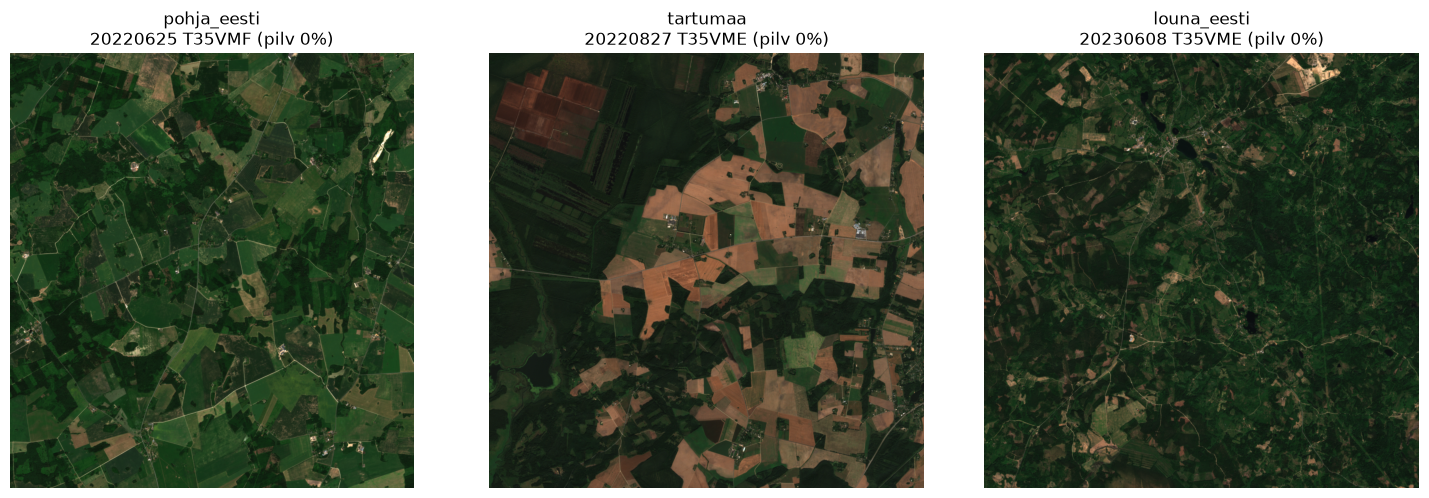

In [30]:
import matplotlib.pyplot as plt

ok = df[df["ok"]].sort_values("cloud_fraction")
areas_ok = ok["area"].unique()
fig, axes = plt.subplots(1, len(areas_ok), figsize=(5 * len(areas_ok), 5), squeeze=False)
for ax, area in zip(axes[0], areas_ok):
    best = ok[ok["area"] == area].iloc[0]          # vähima pilvisusega lõige
    with rasterio.open(best["clip_file"]) as src:
        rgb = src.read([3, 2, 1]).astype("float32")   # B04, B03, B02
    rgb = np.clip((rgb - 1000) / 3000, 0, 1).transpose(1, 2, 0)
    ax.imshow(rgb)
    ax.set_title(f"{area}\n{best['date']} {best['tile']} (pilv {best['cloud_fraction']:.0%})")
    ax.axis("off")
plt.tight_layout()
plt.show()